<a href="https://colab.research.google.com/github/Murcha1990/ML_AI26/blob/main/homeworks/pro/AI_HW1_Regression_with_inference_pro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Домашнее задание №1 (pro)**

В этом домашнем задании вам будет необходимо:
*  обучить модель регрессии для предсказания стоимости автомобилей;


**Оценивание**

Максимальная оценка за ДЗ — **10 баллов**:
- Части 1–5 (EDA, модели, категориальные признаки, Feature Engineering, бизнес-метрика) — 5 баллов;
- Часть 6, оформление репозитория — 2 балла;
- Часть 7, Streamlit-приложение — 3 балла.

**Дедлайн: 2 декабря**

**Примечание**

В каждой части оцениваются как код, **так и ответы на вопросы.**

Если нет одного и/или другого, то часть баллов за соответствующее задание снимается.

In [ ]:
!pip install ydata_profiling

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 47.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 67.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 71.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 15.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 60.9 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6
  Attempting uninstall: llvmlite
    Found existing installation: llvmlite 0.46.0
    Uninstalling llvmlite-0.46.0:
      Successfully uninstalled llvmlite-0.46.0
  Attempting uninstall: numba
    Found existing installation: numba 0.64.0
    Uninstalling numba-0.64.0:
      Successfully uninstalled numba-0.64.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12/12 [ydata_profiling]


In [ ]:
!pip install numpy==2.3.3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 28.1 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.3.5
    Uninstalling numpy-2.3.5:
      Successfully uninstalled numpy-2.3.5


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import seaborn as sns
from ydata_profiling import ProfileReport

from sklearn.linear_model import LinearRegression, Lasso, ElasticNet, Ridge
from sklearn.metrics import r2_score, mean_squared_error as MSE
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder  # для OHE можно использовать и pd.get_dummies
import re
random.seed(42)
np.random.seed(42)

/tmp/ipykernel_810/2058402851.py:6: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


### **Задание 0**
Давайте зафиксируем важный момент.

**Задание 0 (0 баллов).**
Изучите и ответьте на вопрос: для чего фиксируем сиды в домашках?

Для воспроизводимости результатов, но по факту это скам , в большинстве дз , так как обучение на GPU недетерменировано.Но при обучении на проце все работает нормально и воспроизводится без проблем любой эксперимент

# **Часть 1 | EDA**


Первая часть состоит из классических шагов EDA:

- Базовый EDA и обработка признаков (1.4 балла)
- Визуализации признаков и их анализ (0.9 балла)

Всего за эту часть можно набрать 2.3 балла.

## **Простейший EDA и обработка признаков (1.4 балла)**

In [ ]:
df_train = pd.read_csv('https://raw.githubusercontent.com/Murcha1990/MLDS_ML_2022/main/Hometasks/HT1/cars_train.csv')
df_test = pd.read_csv('https://raw.githubusercontent.com/Murcha1990/MLDS_ML_2022/main/Hometasks/HT1/cars_test.csv')

print("Train data shape:", df_train.shape)
print("Test data shape: ", df_test.shape)

Train data shape: (6999, 13)
Test data shape:  (1000, 13)


### **Задание 1 (0.4 балла)**
Выполните операции, направленные на базовое исследование данных:

- [ ] Посмотрите, есть ли в датасете пропуски. Запишите/выведите названия колонок, для которых есть пропущенные значения (0.1 балла)
- [ ] Посмотрите, есть ли в данных явные дубликаты (0.05 балла)
- [ ] Постройте дашборд в одну строку, используя [ydata-profiling](https://github.com/ydataai/ydata-profiling) (0.1 балла)
- [ ] Опишите базовые выводы (какие — выберите сами), используя дашборд (0.15 балла).

In [ ]:
df_full = pd.concat([df_train , df_test])
df_full.isna().sum()


,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage,221
engine,221


**Ваш ответ здесь.**

In [ ]:
df_full[df_full.duplicated()]

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
254,Hyundai Grand i10 Sportz,2017,450000,35000,Petrol,Individual,Manual,First Owner,18.9 kmpl,1197 CC,82 bhp,114Nm@ 4000rpm,5.0
258,Maruti Swift VXI,2012,330000,50000,Petrol,Individual,Manual,Second Owner,18.6 kmpl,1197 CC,85.8 bhp,114Nm@ 4000rpm,5.0
324,Jaguar XE 2016-2019 2.0L Diesel Prestige,2017,2625000,9000,Diesel,Dealer,Automatic,First Owner,13.6 kmpl,1999 CC,177 bhp,430Nm@ 1750-2500rpm,5.0
325,Lexus ES 300h,2019,5150000,20000,Petrol,Dealer,Automatic,First Owner,22.37 kmpl,2487 CC,214.56 bhp,202Nm@ 3600-5200rpm,5.0
326,Jaguar XF 2.0 Diesel Portfolio,2017,3200000,45000,Diesel,Dealer,Automatic,First Owner,19.33 kmpl,1999 CC,177 bhp,430Nm@ 1750-2500rpm,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
966,Honda City S,2011,450000,110000,Petrol,Individual,Manual,Third Owner,16.8 kmpl,1497 CC,116.4 bhp,146Nm@ 4800rpm,5.0
971,Maruti Ertiga SHVS ZDI Plus,2017,750000,50000,Diesel,Individual,Manual,First Owner,24.52 kmpl,1248 CC,88.5 bhp,200Nm@ 1750rpm,7.0
974,Toyota Innova 2.5 G (Diesel) 8 Seater BS IV,2005,310000,200000,Diesel,Individual,Manual,Second Owner,12.8 kmpl,2494 CC,102 bhp,20.4@ 1400-3400(kgm@ rpm),8.0
984,Maruti Ritz VDi,2012,300000,70000,Diesel,Individual,Manual,First Owner,23.2 kmpl,1248 CC,73.94 bhp,190Nm@ 2000rpm,5.0


In [ ]:
profile = ProfileReport(df_full)
profile

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 13/13 [00:00<00:00, 27.00it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

* Может показаться ,что есть противоречие между тем , что всего пропусков 1100 и это 1.1 процент данных, но тут все норм, так как это именно пропущенных ячеек данных , которых всего 7999*13

* Полных совпадений по строкам 607 или 8 процентов всех строк.

* Категориальных столбоц 4 , числовых 5(хотя это какой-то скам , как минимум столбцы с литражом на километр и engine, да и всего столбцов 13 а не 9, но тут просят аналитику по profile)

* В километраже и прайсе явно есть выбросы.

* mileage	engine	max_power	torque - все эти столбцы на самом деле должны нести числовую информацию, но записаны с единицами измерения , поэтому пандас их распознает как текст

* В seats либо есть ошибки , либо это  микроавтобусы какие-то с количеством мест 14.Точнее надо будет смотреть попозже.Но у нас много дизельных машин, поэтому вполне себе может быть правдой.

* Пропуски в основном идут в тех столбцах, которых мы должны считать числовыми, но которые содержат единицы измерения, может при более детальном рассмотрение получится их грамотно заполнить

### **Задание 2 (0.2 балла)**
Проанализируйте статистики датасета.

**Ваша задача:**
- [ ] Посчитайте основные статистики по числовым столбцам для трейна и теста
- [ ] Посчитайте основные статистики по категориальным столбцам для трейна и теста
- [ ] Сравните среднее и медиану внутри `train`, внутри `test` и между собой. О чём могут говорить результаты?
- [ ] Сделайте выводы по статистикам. Отсутствие выводов равносильно по баллам невыполнению задания.

**Подсказка:**

Используйте ``.describe()`` с нужным(и) аргументом(-ами).

In [ ]:
# Ваш код здесь
df_full.describe(include="all")

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
count,7999,7999.000000,7.999000e+03,7.999000e+03,7999,7999,7999,7999,7778,7778,7784,7777,7778.000000
unique,2045,NaN,NaN,NaN,4,3,2,5,392,121,322,439,NaN
top,Maruti Swift Dzire VDI,NaN,NaN,NaN,Diesel,Individual,Manual,First Owner,18.9 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,NaN
freq,128,NaN,NaN,NaN,4327,6663,6972,5210,219,1001,373,522,NaN
mean,NaN,2013.801225,6.368131e+05,6.981073e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.417974
std,NaN,4.048004,8.028019e+05,5.665201e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.960059
min,NaN,1983.000000,2.999900e+04,1.000000e+00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000
25%,NaN,2011.000000,2.534995e+05,3.500000e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.000000
50%,NaN,2015.000000,4.500000e+05,6.000000e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.000000
75%,NaN,2017.000000,6.750000e+05,9.800000e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.000000


In [ ]:
df_train_med = df_train[df_train.select_dtypes(["number"]).columns.to_list()].quantile(0.5)
df_train_mean = df_train[df_train.select_dtypes(["number"]).columns.to_list()].mean()
df_train_comp = pd.concat([df_train_med,df_train_mean],axis = 1)


In [ ]:
df_test_med = df_test[df_test.select_dtypes(["number"]).columns.to_list()].quantile(0.5)
df_test_mean = df_test[df_test.select_dtypes(["number"]).columns.to_list()].mean()
df_test_comp = pd.concat([df_test_med,df_test_mean],axis = 1)
df_test_comp

,0.5,0.0
year,2014.0,2013.681000
selling_price,434999.0,617901.042000
km_driven,61500.0,71393.341000
seats,5.0,5.410805


Ну между трейном и тестом статистики не то чтобы сильно меняются , значит дрифт хотя и есть, но он небольшой, что хорошо.Внутри одной и то же выборки координально отличаются только стоимость продажи, так как скорее всего сильно влияют большие значения , например максимальное значение есть в 10 милионнов.В общем тут явно видно не робастность среднего

### **Задание 3 (0.2 балла)**

- [ ] Посмотрите, есть ли в трейне объекты с одинаковым признаковым описанием (целевую переменную следует исключить). Если есть, то сколько? (0.01 балла)
- [ ] Отобразите такие объекты (0.01 балла)
- [ ] Удалите повторяющиеся строки. Если при одинаковом признаковом описании цены на автомобили отличаются, то оставьте первую строку по этому автомобилю (0.01 балла)
- [ ]  Обновите индексы строк таким образом, чтобы они шли от 0 без пропусков (0.01 балла)
- [ ] Подумайте, могут ли в данных быть другие скрытые дубли? Предложите, как их можно отлавливать. (0.16 балла)

P.S. Тут данные без подвоха, но выводы нам нужны.

In [ ]:
duplicates = df_train[df_train.duplicated(subset=df_train.drop("selling_price",axis = 1), keep=False)]
display(duplicates)
df_train = df_train.drop_duplicates(subset=df_train.drop("selling_price",axis = 1), keep='first')

df_train = df_train.reset_index(drop=True)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
22,Maruti Baleno Delta 1.2,2016,575000,45000,Petrol,Individual,Manual,First Owner,21.4 kmpl,1197 CC,83.1 bhp,115Nm@ 4000rpm,5.0
26,Maruti Omni E MPI STD BS IV,2018,254999,25000,Petrol,Individual,Manual,First Owner,16.8 kmpl,796 CC,34.2 bhp,59Nm@ 2500rpm,8.0
27,Maruti Vitara Brezza LDi Option,2017,670000,70000,Diesel,Individual,Manual,First Owner,24.3 kmpl,1248 CC,88.5 bhp,200Nm@ 1750rpm,5.0
28,Fiat Palio 1.2 ELX,2003,70000,50000,Petrol,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN
29,Maruti Omni 8 Seater BSIV,2012,150000,35000,Petrol,Individual,Manual,Second Owner,14.0 kmpl,796 CC,35 bhp,6.1kgm@ 3000rpm,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6981,Ford Freestyle Titanium Plus Diesel BSIV,2018,750000,24000,Diesel,Individual,Manual,First Owner,24.4 kmpl,1498 CC,98.63 bhp,215Nm@ 1750-3000rpm,5.0
6984,Ford Freestyle Titanium Plus Diesel BSIV,2018,746000,24000,Diesel,Individual,Manual,First Owner,24.4 kmpl,1498 CC,98.63 bhp,215Nm@ 1750-3000rpm,5.0
6989,Maruti Swift Dzire VDI,2015,625000,50000,Diesel,Individual,Manual,First Owner,26.59 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
6997,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57 kmpl,1396 CC,70 bhp,140Nm@ 1800-3000rpm,5.0


Ну наверное могут быть дубли скрытые , например название машины отражено по другому, хотя по факту это та же модель например . Или например данные по точности выгружались по разному , и в mileage или maxpower неправильно округлилось до 2 знаков

In [ ]:
# your code here

In [ ]:
assert df_train.shape == (5840, 13)

### **Задание 4 (0.25 балла)**

Вы могли заметить, что с признаками ``mileage, engine, max_power и torque`` всё не очень хорошо. Они распознаются как строки (можно убедиться в этом, вызвав `data.dtypes`). Однако эти переменные не являются категориальными — они — числа. Соответственно, нужно привести их к числовому виду.

**Задача:**
* [ ] Уберите единицы измерения для признаков ``mileage, engine, max_power``.
* [ ] Приведите тип данных к ``float``.
* [ ] Предобработайте признак `torque` — разделите его на два: собственно `torque` и `max_torque_rpm`. Учтите единицы измерения


**Важно**
- Все действия нужно производить над обоими датасетами — `train` и `test`.

In [ ]:
# your code here
df_train["mileage"] = df_train["mileage"].str[:-5].astype("float32")
df_train["engine"] = df_train["engine"].str[:-3].astype("float32")
# по max_power там есть проблема с тем что у некотрых max_power = 0 и в целом у таких наблюдений четырех такие себе наблюдения.Поэтому удалю их
df_train["max_power"] = df_train["max_power"].str[:-4]
df_train = df_train[df_train["max_power"] != ""]
df_train["max_power"] = df_train["max_power"].astype("float32")

In [ ]:
df_test["mileage"] = df_test["mileage"].str[:-5].astype("float32")
df_test["engine"] = df_test["engine"].str[:-3].astype("float32")
# по max_power там есть проблема с тем что у некотрых max_power = 0 и в целом у таких наблюдений четырех такие себе наблюдения.Поэтому удалю их
df_test["max_power"] = df_test["max_power"].str[:-4]
df_test = df_test[df_test["max_power"] != ""]
df_test["max_power"] = df_test["max_power"].astype("float32")

С torque все сложнее . Во первых там по самому крутящему моменту есть разные единицы измерения(я буду барть соотношение примерно 1 NP = 10KGM , там более точное соотноешние на самом деле , но я чуть принебрег точностью),во вторых там разделитель между первой и второй частью бывают не только через @ но и через at.

In [ ]:
df_train['torque'] = df_train['torque'].str.replace(r'\s+at\s+|@', '@', regex=True)
ser_to_torque = df_train['torque'].str.split('@', expand=True)[0]
ser_to_max_torq = df_train['torque'].str.split('@', expand=True)[1]

In [ ]:
df_train["torque"] = ser_to_torque
df_train["max_torque_rpm"] = ser_to_max_torq

mask_2= (df_train["torque"].str.contains("kgm", case = False , na = False) | df_train["max_torque_rpm"].str.contains("kgm", case = False , na = False))
df_train["torque"] = df_train["torque"].str.replace(r"[A-Za-z]+", "", regex=True)

In [ ]:
mask  = (df_train.index == 633)
df_train.loc[mask , "torque"] = "38.7"
df_train["torque"].iloc[1658] = "400"
mask_1 = (df_train["name"].str.contains("Skoda Octavia"))&(df_train["torque"].str.contains("/"))
df_train.loc[mask_1 , "torque"] = "210"

# Очень здорово придумали составители заданий , вместо чего-то содержательного сидеть в дата сете ошибки искать)))) на работе же этого не хватает, в дз тоже надо накинуть
df_train["torque"] = pd.to_numeric(df_train["torque"])
df_train.loc[mask_2, "torque"] *= 10

/tmp/ipykernel_810/258559463.py:3: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df_train["torque"].iloc[1658] = "400"
/tmp/ipykernel_810/258559463.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFr

In [ ]:
df_train["max_torque_rpm"] = pd.to_numeric(df_train["max_torque_rpm"].str.replace(",", ".", regex=False).str.split("-").str[-1].str.replace(r"[^0-9]+", "", regex=True))

In [ ]:
df_test['torque'] = df_test['torque'].str.replace(r'\s+at\s+|@', '@', regex=True)
ser_to_torque = df_test['torque'].str.split('@', expand=True)[0]
ser_to_max_torq = df_test['torque'].str.split('@', expand=True)[1]
df_test["torque"] = ser_to_torque
df_test["max_torque_rpm"] = ser_to_max_torq

mask_2= (df_test["torque"].str.contains("kgm", case = False , na = False) | df_test["max_torque_rpm"].str.contains("kgm", case = False , na = False))
df_test["torque"] = df_test["torque"].str.replace(r"[A-Za-z]+", "", regex=True)



df_test["torque"].iloc[793] = "110"
mask_1 = (df_test["name"].str.contains("Skoda Octavia"))&(df_test["torque"].str.contains("/"))
df_test.loc[mask_1 , "torque"] = "210"

# Очень здорово придумали составители заданий , вместо чего-то содержательного сидеть в дата сете ошибки искать)))) на работе же этого не хватает, в дз тоже надо накинуть
df_test["torque"] = pd.to_numeric(df_test["torque"])
df_test.loc[mask_2, "torque"] *= 10
df_test["max_torque_rpm"] = pd.to_numeric(df_test["max_torque_rpm"].str.replace(",", ".", regex=False).str.split("-").str[-1].str.replace(r"[^0-9]+", "", regex=True))

/tmp/ipykernel_810/443935476.py:12: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df_test["torque"].iloc[793] = "110"
/tmp/ipykernel_810/443935476.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFr

### **Задание 5 (0.15 балла)**

На первом шаге мы обнаружили пропуски. Давайте избавимся от них.

**Задание:**
- [ ] Заполните пропуски в столбцах медианами. Убедитесь, что после заполнения пропусков не осталось.
- [ ] Почему стоит применять именно медиану? Могли ли мы применить среднее? Обоснуйте свое рассуждение.
- * могли бы , но по одному (как минимум ) из столбцов у нас среднее было не очень хорошее и дрейфовало сильно по трейну тесту.Медианна более устойчивая к выбросам , ее и юзаем
- [ ] Как правильно считать медиану для заполнения? Выберите верное утверждение:

 - По тренировочным данным для `train` и `test`

In [ ]:
# your code here
for column in df_train.select_dtypes("number").columns.to_list():
  fil = df_train[column].quantile(0.5)
  df_train[column] = df_train[column].fillna(fil)
  df_test[column] = df_test[column].fillna(fil)

In [ ]:
df_test.isna().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage,0
engine,0


### **Задание 6 (0.1 балла)**

Теперь, когда не осталось пропусков, давайте преобразуем столбцы к более подходящим типам. А именно столбцы ``engine`` и ``seats`` приведём к `int`.

- [ ] Осуществите приведение столбцов к необходимому типу.
- [ ] Ответьте на вопрос — почему ``seats`` (хоть мы этого и не делаем) можно рассматривать как категориальную переменную?

In [ ]:
# your code here
df_train[["engine","seats"]] = df_train[["engine","seats"]].astype("int8")
df_test[["engine","seats"]] = df_test[["engine","seats"]].astype("int8")

Но можно подумат о том, что  если мы сделаем категориальные , то условно мы можем разбить на классы:джип , спорткар, дефолтная 4ех местная , миним автобус и т.д. То есть просто отразить класс машины через количество мест

Но вообще это плохая идея, класс машины уже заложен в названии, но например есть машины с одинаковым названием и одинаковым движком, но например третьим рядос сидений .Тогда смысл в этом теряется

### **Задание 7 (0.1 балла)**

Снова вызовите метод describe и проанализируйте статистики.

**Ответьте на вопрос:**
- [ ] Есть ли основания предполагать, что заполнение пропусков сдвинуло наши распределения? Могло ли это вообще возникнуть?

In [ ]:
df_full_new = pd.concat([df_train , df_test])
df_full_new.describe()

,year,selling_price,km_driven,mileage,engine,max_power,torque,seats,max_torque_rpm
count,6836.000000,6.836000e+03,6.836000e+03,6836.000000,6836.000000,6836.000000,6836.000000,6836.000000,6.836000e+03
mean,2013.467379,5.369915e+05,7.357602e+04,19.419538,-22.443827,88.375221,176.022703,5.423054,7.436934e+03
std,4.081785,5.745241e+05,5.853877e+04,3.980654,65.490051,32.106369,107.601323,0.972220,2.565773e+05
min,1983.000000,2.999900e+04,1.000000e+00,0.000000,-125.000000,32.799999,48.000000,2.000000,5.000000e+02
25%,2011.000000,2.500000e+05,3.800000e+04,16.799999,-81.000000,68.000000,111.800000,5.000000,2.400000e+03
50%,2014.000000,4.099990e+05,6.877500e+04,19.400000,-32.000000,81.860001,161.000000,5.000000,3.000000e+03
75%,2017.000000,6.500000e+05,1.000000e+05,22.299999,28.000000,100.000000,204.000000,5.000000,4.000000e+03
max,2020.000000,1.000000e+07,2.360457e+06,42.000000,126.000000,400.000000,1900.000000,14.000000,1.500450e+07


In [ ]:
df_full.describe(include = "all")

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
count,7999,7999.000000,7.999000e+03,7.999000e+03,7999,7999,7999,7999,7778,7778,7784,7777,7778.000000
unique,2045,NaN,NaN,NaN,4,3,2,5,392,121,322,439,NaN
top,Maruti Swift Dzire VDI,NaN,NaN,NaN,Diesel,Individual,Manual,First Owner,18.9 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,NaN
freq,128,NaN,NaN,NaN,4327,6663,6972,5210,219,1001,373,522,NaN
mean,NaN,2013.801225,6.368131e+05,6.981073e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.417974
std,NaN,4.048004,8.028019e+05,5.665201e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.960059
min,NaN,1983.000000,2.999900e+04,1.000000e+00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000
25%,NaN,2011.000000,2.534995e+05,3.500000e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.000000
50%,NaN,2015.000000,4.500000e+05,6.000000e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.000000
75%,NaN,2017.000000,6.750000e+05,9.800000e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.000000


Статистики некоторые , например среднее , наверняка медиана подвинула .Но само распределение данных я думаю глобально нет, у нас был всего процент пропусков и их мы заполнили устойчивой статистикой, поэтому я думаю данные не сильно изменились, по describe это и видно собственно

Но тут тяжело давать оценки по describe , так как мы удаляли дубликаты, и нечестно сравнивать табличку до удаления дубликатов и после

## **Визуализации и корреляция (0.9 балла)**

Визуализация данных — важный шаг в работе. Визуализировать данные необходимо, например, чтобы:

- Оценить распределения признаков самих по себе (это может натолкнуть вас на мысли о модели, которую можно использовать)
- Сравнить распределения на `train` и `test` — чтобы проверить, насколько информация, на которой вы будете обучаться согласуется с той, на которой модель должна работать
- Оценить есть ли явная связь признаков с целевой переменной

**Важно:**

Если распределения на `train` и `test` не совпадают, это не значит, что нужно перемешивать данные! Более корректно актуализировать задачу и уточнить, а не устарели ли данные `train`.

**Если вы будете подгонять распределения, то можете встретиться с переобучением!**

### **Задание 8 (0.25 балла)**

Шаг 1.
- [ ] Воспользуйтесь `pairplot` из библиотеки `seaborn`, чтобы визуализировать попарные распределения числовых признаков для `train`
- [ ] По полученному графику ответьте на вопросы:
 - Можно ли предположить на основе распределений связь признаков с целевой переменной?
 Ну кажется , что по отдельности минимальное количество признаков явно линейно связаны с таргетом хотя бы как-то
 - Можно ли на основе распределений выдвинуть гипотезу о корреляциях признаков?
 Кажется, что корреляция по болшинству признаков будет слабая.

Шаг 2.

- [ ] Постройте pairplot по тестовым данным
- [ ] Ответьте на вопрос "Похожими ли оказались совокупности при разделении на трейн и тест?"
Да, сильного отличия между тренировочными данными и тестовыми с точки зрения совместного попарного распределения признаков кажется, что нет


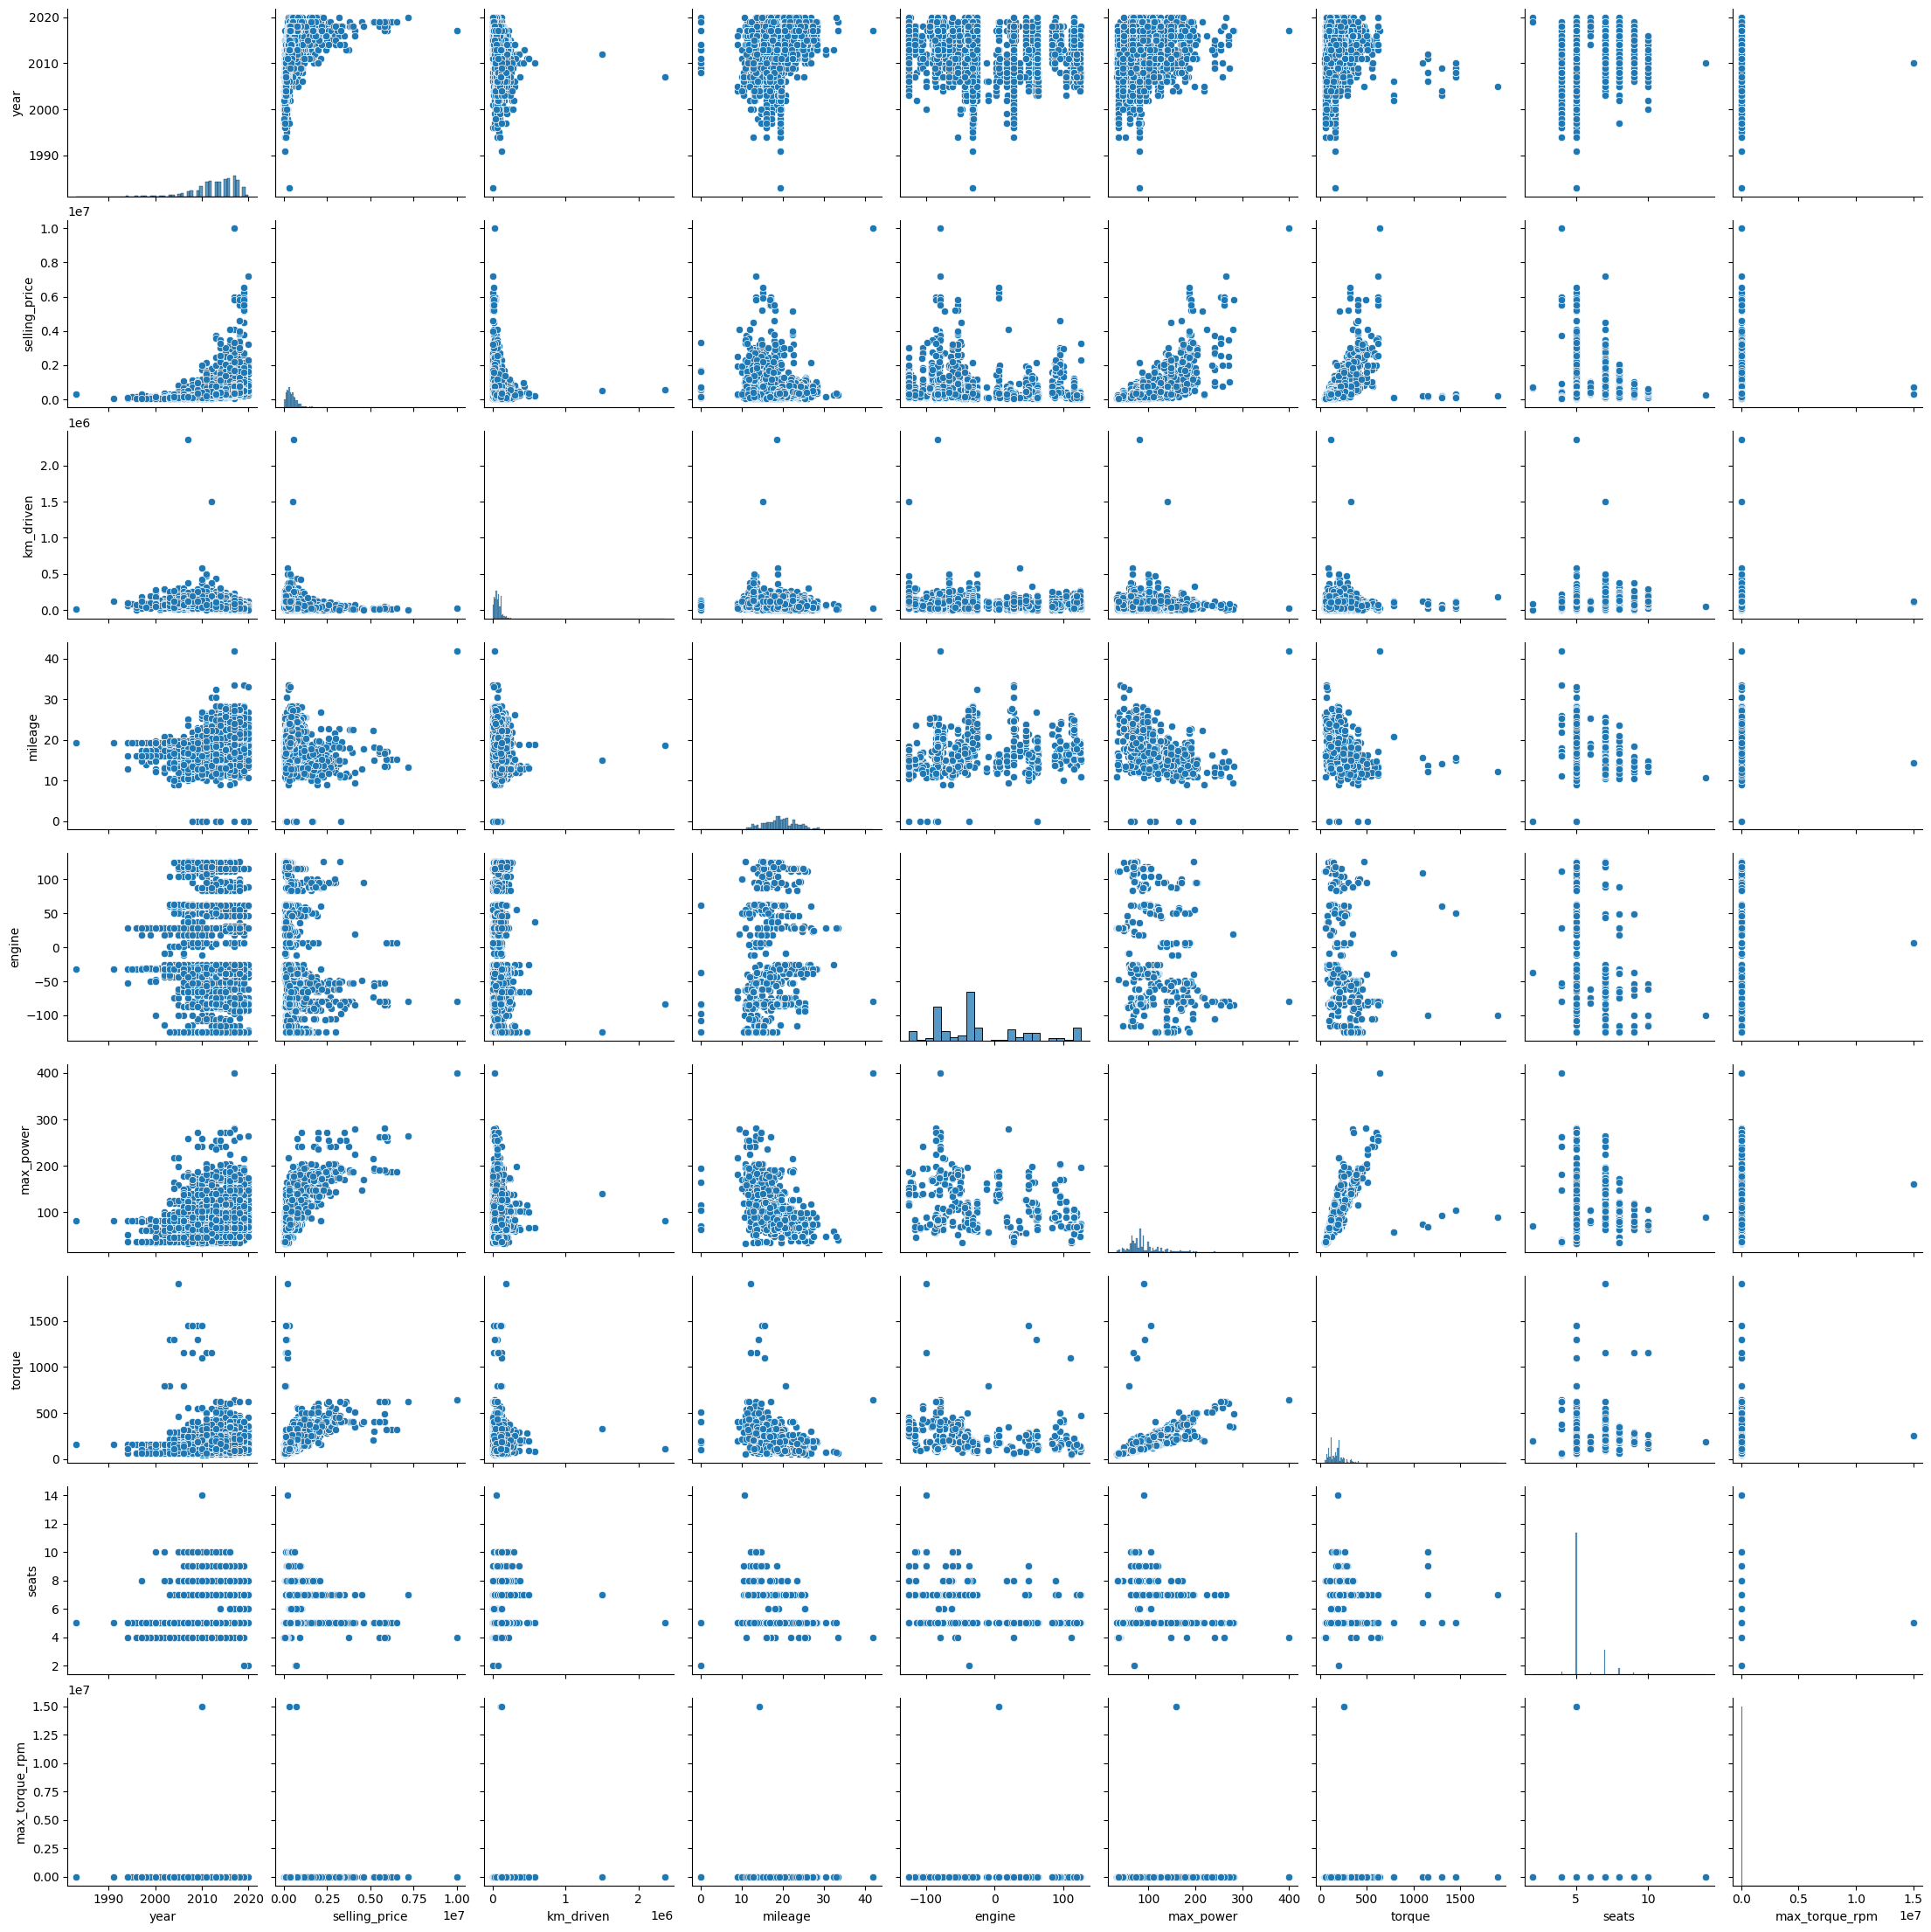

In [ ]:
# your code here
sns.pairplot(df_train)

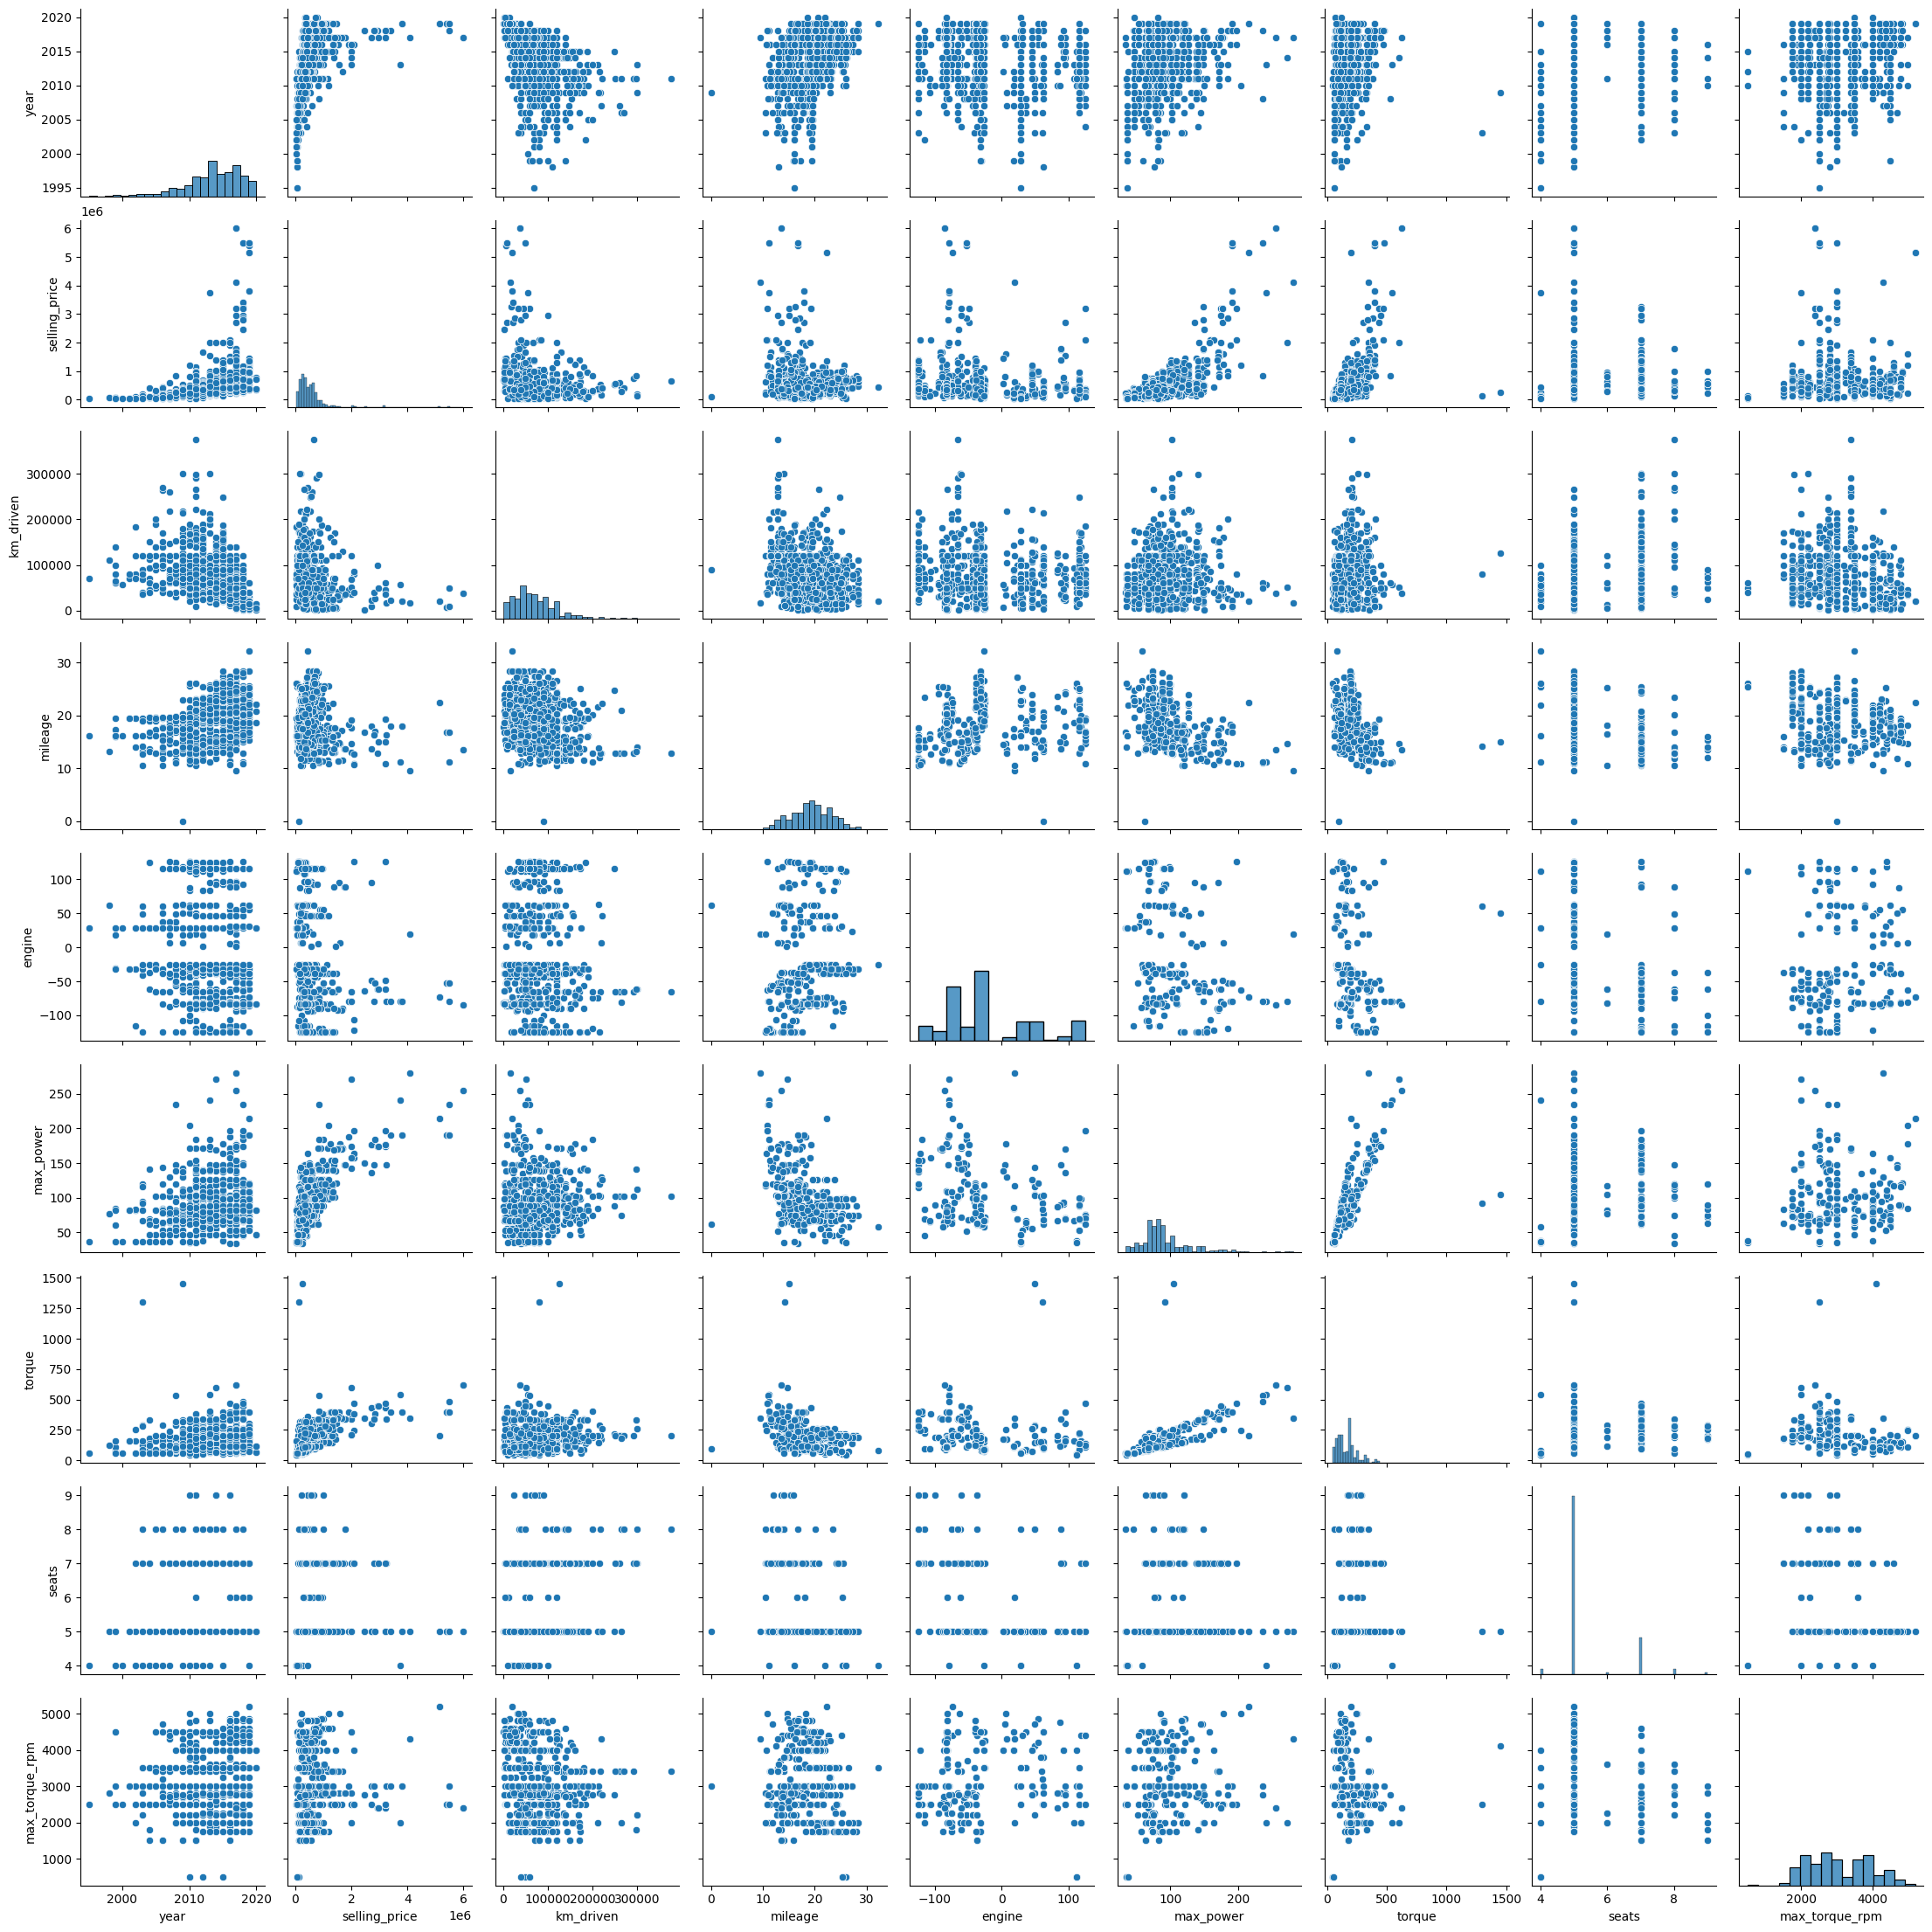

In [ ]:
sns.pairplot(df_test)

Какие-то хотя бы минимально наблюдаемые зависимости есть только у max_power и torque.

### **Задание 9 (0.2 балла)**

Итак, вы выдвинули гипотезы о наличии связи. Теперь давайте оценим эту связь в числах.

**Задание:**
- [ ] Получите значения коэффициента корреляции Пирсона для тренировочного набора данных при помощи `DataFrame.corr()`
- [ ] По полученным корреляциям постройте тепловую карту (`heatmap` из библиотеки seaborn)

<Axes: >

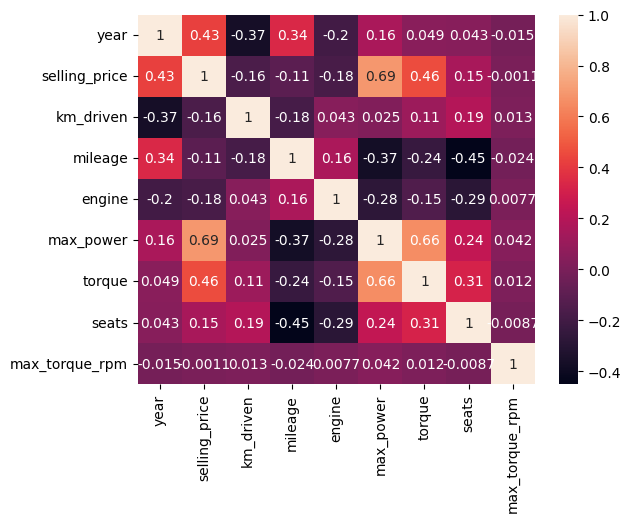

In [ ]:
# your code here
sns.heatmap(df_train.select_dtypes(["number"]).corr(),annot = True)

In [ ]:
numpy_matrix = df_train.select_dtypes(["number"]).to_numpy()
matrix_bef_sum = numpy_matrix[:,1:5] - numpy_matrix[:,1].reshape(-1,1)
np.sum(matrix_bef_sum , axis = 0)

array([ 0.00000000e+00, -2.62140057e+09, -3.05285952e+09, -3.05310309e+09])

- [ ] Ответьте на вопросы:
 - Какие 2 признака наименее скоррелированы между собой?

 max_torque и engine
 - Между какими наблюдается довольно сильная положительная линейная зависимость?

 selling_price и torque
 - Правильно ли, опираясь на данные, утверждать, что чем меньше год, тем, скорее всего, больше километров проехала машина к дате продажи?

 Корреляция не равно каузация.Утверюдать так нельзя
 - Изучите типы корреляций в `DataFrame.corr()`. Какую вы использовали по умолчанию?

 По умолчанию юзается Пирсон корреляция.

`Your answer here`

### **Задание 10 (0.35 балла)**

По умолчанию `DataFrame.corr` возвращает корреляцию Пирсона, говорящую о линейной взаимосвязи. Но зависимости существуют не только линейные! В этой задаче, попробуйте другие способы вычисления корреляций.

- [ ] Реализуйте корреляцию Спирмена/Кендалла (на выбор) без использования библиотек (можно пользоваться только `numpy`). Сравните результаты вычисления с библиотечной реализацией
- [ ] Сделайте выводы


Постройте матрицу корреляции [phik](https://pypi.org/project/phik/)
- [ ] Проинтерпретируйте результаты

In [ ]:
# your code here
def corr_spear(df):
  matrix = df.to_numpy()
  df_rank = matrix.argsort(axis = 0).argsort(axis = 0) # идею подглядел в интернетах

  corr_matrix_init = np.eye(df.shape[1])
  for i in range(df_rank.shape[1]):
    corr_series = df_rank[:, i+1:] - df_rank[:, i].reshape(-1, 1)
    cor_i_seria = np.sum(corr_series**2 , axis = 0)
    n = matrix.shape[0]
    corr_stat = 1 - ((6*cor_i_seria) / (n*(n**2-1)))
    corr_matrix_init[i+1: , i] = corr_stat
    corr_matrix_init[i , i+1:] = corr_stat
  return corr_matrix_init
# Но вообще получается , что двойной аргосрт, разные ранги присваивает одинаковым значениям, но вроде это будет не сильно влиять и в целом все будет более менее норм

In [ ]:
corr_sp = corr_spear(df_train.select_dtypes(["number"]))
corr_sp

array([[ 1.        ,  0.70432927, -0.56799056,  0.34357295, -0.22936514,
         0.16450669,  0.09609189,  0.0462409 ,  0.07688488],
       [ 0.70432927,  1.        , -0.29654574,  0.02594684, -0.34728601,
         0.61286593,  0.57999302,  0.22527755, -0.12175138],
       [-0.56799056, -0.29654574,  1.        , -0.19784922,  0.10685628,
         0.03961229,  0.24365385,  0.10540398, -0.31008185],
       [ 0.34357295,  0.02594684, -0.19784922,  1.        ,  0.24434847,
        -0.30900618, -0.16636065, -0.30428211, -0.18422409],
       [-0.22936514, -0.34728601,  0.10685628,  0.24434847,  1.        ,
        -0.36849884, -0.23571785, -0.23979363, -0.08623861],
       [ 0.16450669,  0.61286593,  0.03961229, -0.30900618, -0.36849884,
         1.        ,  0.78091378,  0.20092082, -0.01972905],
       [ 0.09609189,  0.57999302,  0.24365385, -0.16636065, -0.23571785,
         0.78091378,  1.        ,  0.28562026, -0.51293709],
       [ 0.0462409 ,  0.22527755,  0.10540398, -0.30428211, -0

In [ ]:
df_train.select_dtypes(["number"]).corr(method = "spearman")

,year,selling_price,km_driven,mileage,engine,max_power,torque,seats,max_torque_rpm
year,1.000000,0.706840,-0.569544,0.345661,-0.229681,0.165857,0.097581,0.048956,0.076049
selling_price,0.706840,1.000000,-0.295368,0.025580,-0.346357,0.612649,0.579649,0.318444,-0.120853
km_driven,-0.569544,-0.295368,1.000000,-0.198236,0.105071,0.040999,0.245627,0.195109,-0.314565
mileage,0.345661,0.025580,-0.198236,1.000000,0.245919,-0.309124,-0.166228,-0.435170,-0.185033
engine,-0.229681,-0.346357,0.105071,0.245919,1.000000,-0.369064,-0.236142,-0.327046,-0.086889
max_power,0.165857,0.612649,0.040999,-0.309124,-0.369064,1.000000,0.781676,0.304864,-0.018924
torque,0.097581,0.579649,0.245627,-0.166228,-0.236142,0.781676,1.000000,0.438758,-0.514553
seats,0.048956,0.318444,0.195109,-0.435170,-0.327046,0.304864,0.438758,1.000000,-0.191583
max_torque_rpm,0.076049,-0.120853,-0.314565,-0.185033,-0.086889,-0.018924,-0.514553,-0.191583,1.000000


Ответы сильно похожи.корреляции не сильно отличаются между собой, значит реализации близки друг к другу.В целом тут видно что корреляция между стоиомстью и годом еще сильнее , чем мы думали раньше (возможно придется делать какое-то монотонное преобразование).В целом тут можно заметить , что самые сильные корреляции так и остались самыми сильными корреляциями.

interval columns not set, guessing: ['year', 'selling_price', 'km_driven', 'mileage', 'engine', 'max_power', 'torque', 'seats', 'max_torque_rpm']


/usr/local/lib/python3.13/dist-packages/phik/data_quality.py:59: UserWarning: The number of unique values of variable name is large: 1923. Are you sure this is not an interval variable? Analysis for pairs of variables including name can be slow.
  warnings.warn(


<Axes: >

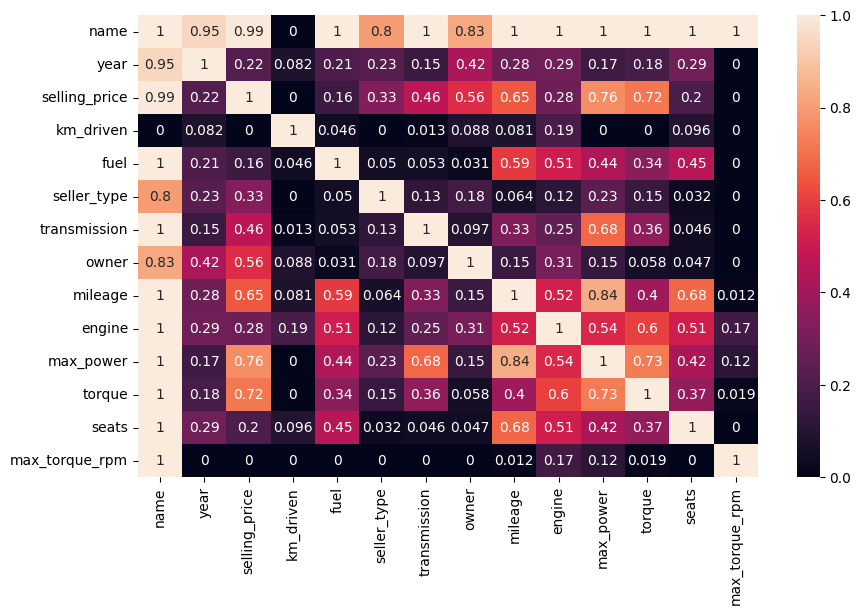

In [ ]:
import phik
phik_matrix = df_train.phik_matrix()
plt.figure(figsize = (10,6))
sns.heatmap(phik_matrix,annot=True)


Тут с name все понятно.Все характеристики машины очень сильно зависит от самоей модели машины.Тут видно что и все остальные кат столбцы тоже неплохо связаны с таргетом.

### **Задание 11 (0.1 балла)**

Если вам кажется, что мы не попросили вас нарисовать какие-то очень важные зависимости, нарисуйте их **и поясните.**

- [ ] Постройте хотя бы одну дополнительную визуализацию и объясните, что она показывает и почему это важно.

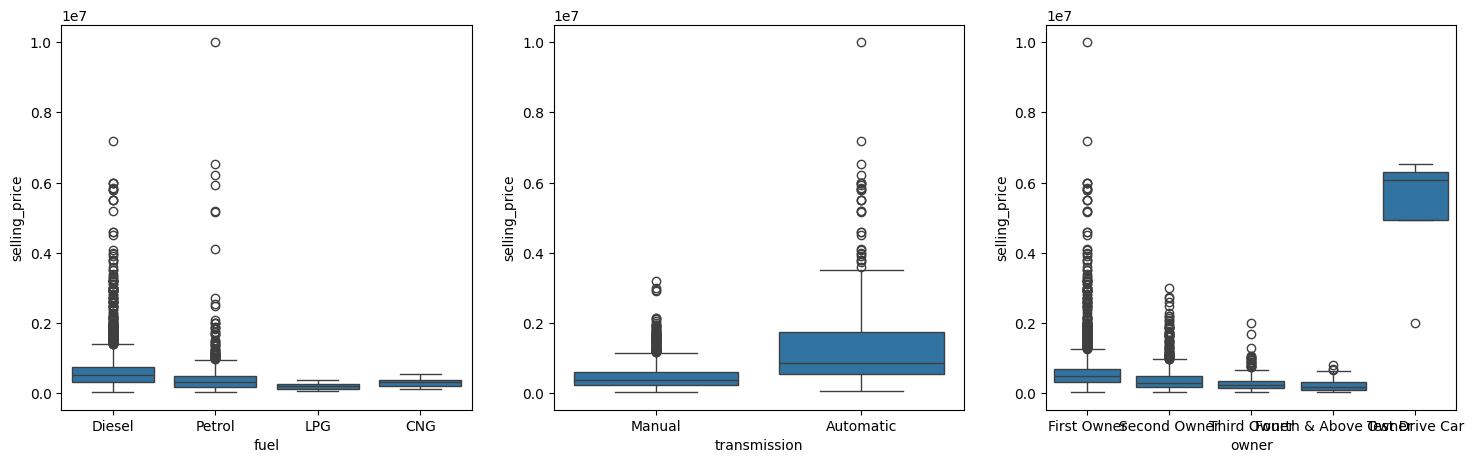

In [ ]:
# your code here
fig, axes =plt.subplots(1,3,figsize=(18, 5))
sns.boxplot(data=df_train, x='fuel', y='selling_price', ax=axes[0])
sns.boxplot(data=df_train, x='transmission', y='selling_price', ax=axes[1])
sns.boxplot(data=df_train, x='owner', y='selling_price', ax=axes[2])

plt.show()

* Тут например видно , что у нас дизельные автомобили в целом сильно дороже в сравнении с бензиновыми .Но и там и там достаточно много выбросов.

* По трансмисии тоже такая же картина видна , но тут сильно manual у нас больше , поэтому это тоже должна быть сильная фича скорее всего

* По owner тоже есть какая то странная категория

Теперь мы узнали , что мы сможем отдельно как-то подсветить дополнительно именно эти категории, возможно добавить их взаимодейтсвие с другими и получить результат получше

# **Часть 2 (1.4 балла) | Модель только на вещественных признаках**

В этой части вам предстоит обучить модель только на вещественных признаках. Почему только на них?

Чем больше признаковое пространство — тем сложнее модель. А чем модель проще — тем лучше для скорости работы и интерпретации признаков.

За задания этой части вы можете набрать 1.4 балла.

### **Задание 12 (0.05 балла)**

Сделайте тренировочный и тестовый наборы. Они уже даны, достаточно просто отделить целевой признак. Перед разбиением создайте копию датафрейма, который будет хранить только вещественные признаки и используйте его (то есть категориальные столбцы (все, кроме seats) необходимо удалить).

В переменные y_train и y_test запишите значения целевых переменных. Используйте уже имеющиеся данные train и test. Если считаете уместным применить какую-то более хитрую технику разбиения — примените, но опишите, зачем.

In [ ]:
df_real_train = df_train.select_dtypes(["number"])
df_real_test = df_test.select_dtypes(["number"])
y_train = df_real_train["selling_price"]
X_train = df_real_train.drop(columns=["selling_price"])

In [ ]:
# опишите выбранные вещественные признаки
# ну мы же уже делали анализ, в процессе я думаю достаточно пояснений

In [ ]:
y_test = df_real_test["selling_price"]
X_test = df_real_test.drop(columns=["selling_price"])

### **Задание 13 (0.2 балла)**

Построим нашу первую модель!
- [ ] Обучите классическую линейную регрессию с дефолтными параметрами. Посчитайте $R^2$ и $MSE$ для трейна и для теста.
- [ ] Сделайте выводы по значениям метрик качества.

**Примечание:**

Здесь и далее $R^2$ и $MSE$ для трейна и для теста выводите везде, где требуется обучать модели, даже если в явном виде этого не просят. Иначе непонятно, как понять, насколько успешны наши эксперименты.

In [ ]:
# your code here
from sklearn.metrics import mean_squared_error,r2_score
model  = LinearRegression()
model.fit(X_train , y_train)
train_preds=model.predict(X_train)
test_preds = model.predict(X_test)
MSE_train = mean_squared_error(y_train , train_preds)
MSE_test = mean_squared_error(y_test , test_preds)
R2_test = r2_score(y_test , test_preds)
R2_train= r2_score(y_train , train_preds)
print(f"r2_test {R2_test} , r2_train {R2_train} , MSE train {MSE_train} , MSE test {MSE_test}")

r2_test 0.5954272001911091 , r2_train 0.5961190571651178 , MSE train 115820679951.7152 , MSE test 232559998164.74628


Ну ИМЕННО ПО MSE сделать выводы тяжеловато.R^2 не прям хорошей получилась.Но она не сильно изменилась в зависимости от трейна и теста , значит в плане именно оьяснения дисперсии трейн и тест модель поняла примерно одинаково.Чего нельзя сказать об абсолютных значениях , MSE на тесте примерно в 2 раза больше.

### **Задание 14 (0.25 балла)**

**Шаг 1 (0.15 балла)**
- [ ] Реализуйте $R^2$ руками. Приведите формулу $R^2$ и объясните каждую компоненту метрики

In [ ]:
def R2(y_true , y_pred):
  mse = np.sum((y_true-y_pred)**2)
  mmm_mavrodi = np.sum((y_true-y_true.mean())**2)
  return 1 -  mse / mmm_mavrodi

знаменатель отражает исходную вариативность целевой переменной до применения модели.А Mse показывает насколько хорошо именно модель наша отработала .

**Шаг 2 (0.1 балла)**

- [ ] Реализуйте [$\text{adjusted}-R^2$](https://en.wikipedia.org/wiki/Coefficient_of_determination).
- [ ] Объясните, когда применяется $\text{adjusted}-R^2$?

In [ ]:
# your code here
def adj_R2(y_true, y_pred, k):
    n=len(y_true)
    r2 = R2(y_true, y_pred)
    return 1 - (1 - r2) * (n - 1) / (n - k - 1)

Ну когда мы хотим сравнить моделис  добавлнием признаков , так как R2 при добавлении признаков не уменьшается , а R2 по факту штраф вводит за колво признаков

### **Задание 15 (0.05 балла)**

Всегда есть место совершенству. Поэтому давайте попробуем улучшить модель при помощи стандартизации признаков.

- [ ] Стандартизируйте значения в тренировочных и тестовых данных. Стандартизатор **обучайте только на `train`**.

In [ ]:
# your code here
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_norm = scaler.fit_transform(X_train)
X_test_norm=scaler.transform(X_test)
model.fit(X_train_norm , y_train)
y_norm_pred_test = model.predict(X_test_norm)
MSE_test_norm = mean_squared_error(y_test, y_norm_pred_test)
R2_test_norm = r2_score(y_test , y_norm_pred_test)
print(f"r2_test {R2_test_norm} ,  MSE train {MSE_test_norm} ")

r2_test 0.5954272001913362 ,  MSE train 232559998164.61572 


### **Задание 16 (0.1 балла)**

Хотя стандартизация не помогла сильно прибавить в качестве, она открыла возможность интерпретировать важность признаков в модели. Правило интерпретации такое:

Чем больше коэффициент $\beta_i$ по модулю, тем важнее признак.

**Ответьте на вопрос:**

- [ ] Какой признак оказался наиболее информативным в предсказании цены?

MAX_power


In [ ]:
# your code here
print(X_test.columns)
print(model.coef_)
print(max(model.coef_))

Index(['year', 'km_driven', 'mileage', 'engine', 'max_power', 'torque',
       'seats', 'max_torque_rpm'],
      dtype='object')
[160951.42899045 -40277.68634171  13011.93274053  37563.64147329
 345976.8290671   23629.45830346   6062.87104168 -12392.55118075]
345976.8290671046


### **Задание 17 (0.2 балла)**

Попробуем улучшить нашу модель с помощью применения регуляризации. Для этого воспользуемся `Lasso` регрессией.  Кроме того, попробуйте использовать её теоретическое свойство отбора признаков, за счет зануления незначимых коэффициентов.

**Задание:**

- [ ] Обучите Lasso регрессию на тренировочном наборе данных со стандартизованными признаками. Оцените её качество
- [ ] Проверьте, занулила ли L1-регуляризация с параметрами по умолчанию какие-нибудь веса? Предположите почему.

In [ ]:
# your code here
from sklearn import linear_model
model_lasso = linear_model.Lasso(alpha = 100)
model_lasso.fit(X_train_norm,y_train)
y_lasso_pred_test = model_lasso.predict(X_test_norm)
MSE_test_lasso = mean_squared_error(y_test, y_lasso_pred_test)
R2_test_lasso = r2_score(y_test , y_lasso_pred_test)
print(f"r2_test {R2_test_lasso} ,  MSE train {MSE_test_lasso} " , model_lasso.coef_)


r2_test 0.5953593804122368 ,  MSE train 232598982910.2791  [160987.94501648 -40151.34080395  12771.83876109  37378.9882174
 345776.77727775  23634.64417995   5823.59088196 -12291.72904577]


Тут на самом деле alpha влияет просто не зануляет.Если ставить огромный alpha 100000, то зануление пойдет , но даже если ставить высокйи alpha =100 - этого все равно не хватит , чтобы занулить хотя бы один коэфицент

Думаю,потому что после нормализации нет проблем с гиганскими кэфами, скорее всего все данные у нас реально значими и как то полезно влияют на прогноз.

### **Задание 18. Финальный рывок (0.3 балла)**

До этого мы с вами использовали `train` для обучения и `test` для прогнозирования. Но у нас есть ещё одна задача — подобрать оптимальные параметры модели. Для этого используем кросс-валидацию, описанную на семинарах.

Кроме того, выжмем максимум из модификаций регрессии. Построим `ElasticNet`. И сделаем всё по порядку.

**Ваша задача 1:**

- [ ] Перебором по сетке (с 10 фолдами) подберите оптимальные параметры для Lasso-регрессии. Вам пригодится класс [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).
- [ ] Ответьте на вопросы:
 - Сколько грид-сёрчу пришлось обучать моделей?
 - Что значит каждый параметр `param_grid`, который вы заполняли для `GridSearch`? Опишите каждый
 - Какой коэффициент регуляризации у лучшей из перебранных моделей? Занулились ли какие-нибудь из весов при такой регуляризации?

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Lasso, ElasticNet
parameters_lasso = {"alpha": [0.0001, 0.001, 1,0.01, 0.1,100]} # ну собственно просто сила регуляризации
model_lasso = Lasso()
grid_lasso = GridSearchCV(model_lasso,parameters_lasso,cv=10,
    scoring=["r2","neg_mean_squared_error"],refit="r2")
grid_lasso.fit(X_train_norm, y_train)
print(f"Количество обучений {5 * 10}")
best_lasso = grid_lasso.best_estimator_
print(f"Количество нулевых коэфициентов {np.sum(best_lasso.coef_ == 0)} , лучшая альфа {best_lasso.alpha}")
pred_grid = grid_lasso.best_estimator_.predict(X_test_norm)
MSE_test_grid= mean_squared_error(y_test, pred_grid)
R2_test_grid = r2_score(y_test , pred_grid)
print(f"r2_test {R2_test_grid} ,  MSE test {MSE_test_grid} ")

Количество обучений 50
Количество нулевых коэфициентов 0 , лучшая альфа 100
r2_test 0.5953593804122368 ,  MSE test 232598982910.2791 


**Ваша задача 2:**

- [ ] Перебором по сетке (с 10 фолдами) подберите оптимальные параметры для [ElasticNet](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html) регрессии.
- [ ] Ответьте на вопросы:
 - Сколько грид-сёрчу пришлось обучать моделей?
 - Какие гиперпараметры соответствуют лучшей (по выбранной метрике качества) из перебранных моделей?

In [ ]:
# your code here

parameters_ela = {"alpha": [0.0001, 0.001, 0.01, 0.1, 1,5,100],"l1_ratio": [0.0001, 0.001, 0.01, 0.1, 1]}
model_ela = ElasticNet()
grid_ela = GridSearchCV(model_ela,parameters_ela,cv=10,scoring=["r2", "neg_mean_squared_error"],refit="neg_mean_squared_error",)
grid_ela.fit(X_train_norm, y_train)

print(f"Количество обучений {5 * 10*5}")
print("Лучшие l1", grid_ela.best_estimator_.l1_ratio , "Лучшие альфа" , grid_ela.best_estimator_.alpha)
pred_ela = grid_ela.best_estimator_.predict(X_test_norm)
MSE_test_ela= mean_squared_error(y_test, pred_ela)
R2_test_ela = r2_score(y_test , pred_ela)
print(f"r2_test {R2_test_grid} ,  MSE test {MSE_test_ela} ")


Количество обучений 250
Лучшие l1 1 Лучшие альфа 100
r2_test 0.5953593804122368 ,  MSE test 232598982910.2791 


### **Задание 19 (0.25 балла)**

Итак, вы обучили все варианты регуляризаций, доступные в sklearn, но не все, что мы обсудили на занятии! Следующее задание — о забытой $L0$-регуляризации.

Задача линейной регрессии с $L0$-регуляризацией:

$$\min_{w}\; \frac{1}{n}\|y - Xw\|_2^2 + \lambda \|w\|_0, \qquad \|w\|_0 = \#\{j : w_j \neq 0\}.$$

Штраф $\|w\|_0$ разрывный и невыпуклый, поэтому градиентным спуском «в лоб» задачу не решить. **Выберите один** из способов (или предложите свой и обоснуйте его):

1. **Полный перебор подмножеств (best subset selection).** Для каждого подмножества признаков $S$ обучите МНК только на признаках из $S$ (веса $\hat w_S$) и выберите
$$S^* = \arg\min_{S}\; \frac{1}{n}\|y - X_S \hat w_S\|_2^2 + \lambda |S|.$$
Перебор $2^d$ подмножеств реален при небольшом числе признаков $d$ (у нас вещественных признаков меньше десяти).

2. **Жадный отбор (forward / backward stepwise).** Начните с пустого (полного) набора признаков и на каждом шаге добавляйте (удаляйте) тот признак, который сильнее всего уменьшает $\frac{1}{n}\|y - X_S \hat w_S\|_2^2 + \lambda |S|$. Остановитесь, когда функционал перестанет уменьшаться.

3. **Iterative Hard Thresholding (проксимальный градиентный спуск).** Сделайте шаг градиентного спуска по MSE с шагом $\eta$, затем занулите малые веса:
$$z = w^{(t)} - \eta\, \nabla_w \tfrac{1}{n}\|y - Xw^{(t)}\|_2^2, \qquad w^{(t+1)}_j = z_j \cdot \mathbb{1}\left[|z_j| > \sqrt{2\eta\lambda}\right].$$

4. **Стохастические «ворота» с hard concrete распределением** ([Louizos et al., 2018](https://arxiv.org/abs/1712.01312)). Веса параметризуются как $w = \tilde w \odot z$, где $z_j \in [0, 1]$:
$$u_j \sim U(0,1),\quad s_j = \sigma\!\left(\frac{\log u_j - \log(1-u_j) + \log\alpha_j}{\beta}\right),\quad z_j = \min\big(1, \max(0,\, s_j(\zeta-\gamma)+\gamma)\big),$$
а недифференцируемый $\|w\|_0$ заменяется на его матожидание $\sum_j P(z_j \neq 0)$:
$$\min_{\tilde w,\, \log\alpha}\; \mathbb{E}_u\!\left[\frac{1}{n}\|y - X(\tilde w \odot z)\|_2^2\right] + \lambda\sum_{j}\sigma\!\left(\log\alpha_j - \beta\log\frac{-\gamma}{\zeta}\right).$$
Типичные значения: $\beta = \frac{2}{3},\ \gamma = -0.1,\ \zeta = 1.1$. Оптимизируйте градиентным спуском (например, в PyTorch). На инференсе используйте детерминированные ворота $z_j = \min\big(1, \max(0,\, \sigma(\log\alpha_j)(\zeta-\gamma)+\gamma)\big)$.

Для способов 3 и 4 признаки должны быть стандартизованы.

**Ваша задача:**
- [ ] Реализуйте модель с $L0$-регуляризацией одним из способов выше.
- [ ] Обучите модель при нескольких значениях $\lambda$ и проанализируйте, как меняются число ненулевых весов и качество ($R^2$ и $MSE$ на трейне и тесте).

**Важно:**

Несмотря на то что L0 не реализована в стандартных пакетах, концепция данной регуляризации не является мертвой. Она встречается в статьях и экспериментах.

In [ ]:
# your code here
X_tr = np.asarray(X_train_norm)
X_te = np.asarray(X_test_norm)
y_tr = np.asarray(y_train).ravel()
y_te = np.asarray(y_test).ravel()

def forward_selection(X, y, lambd):
    selected = []
    remaining = list(range(X.shape[1]))

    def objective(features):
        if len(features) == 0:
            pred = np.full(len(y), np.mean(y))
        else:
            model = LinearRegression()
            model.fit(X[:, features], y)
            pred = model.predict(X[:, features])

        return mean_squared_error(y, pred) + lambd * len(features)

    current_loss = objective(selected)

    while remaining:
        best_feature = None
        best_loss = current_loss

        for feature in remaining:
            candidate = selected + [feature]
            loss = objective(candidate)

            if loss < best_loss:
                best_loss = loss
                best_feature = feature

        if best_feature is None:
            break

        selected.append(best_feature)
        remaining.remove(best_feature)
        current_loss = best_loss

    return selected

lambdas = [0, 0.001, 0.01, 0.1, 1, 10,100,1000,10000,80000,70000,100000,300000,700000,800000,1000000,700000000,800000000,900000000,1000000000]
results = []

for lambd in lambdas:
    features = forward_selection(X_tr, y_tr, lambd)

    if features:
        model = LinearRegression()
        model.fit(X_tr[:, features], y_tr)
        pred_train = model.predict(X_tr[:, features])
        pred_test = model.predict(X_te[:, features])
    else:
        pred_train = np.full(len(y_tr), np.mean(y_tr))
        pred_test = np.full(len(y_te), np.mean(y_tr))

    results.append({
        "Lambda": lambd,
        "Non-zero weights": len(features),
        "Selected features": features,
        "Train R2": r2_score(y_tr, pred_train),
        "Test R2": r2_score(y_te, pred_test),
        "Train MSE": mean_squared_error(y_tr, pred_train),
        "Test MSE": mean_squared_error(y_te, pred_test)
    })

results_df = pd.DataFrame(results)
display(results_df)


,Lambda,Non-zero weights,Selected features,Train R2,Test R2,Train MSE,Test MSE
0,0.000000e+00,8,"[4, 0, 3, 1, 5, 7, 2, 6]",0.596119,0.595427,1.158207e+11,2.325600e+11
1,1.000000e-03,8,"[4, 0, 3, 1, 5, 7, 2, 6]",0.596119,0.595427,1.158207e+11,2.325600e+11
2,1.000000e-02,8,"[4, 0, 3, 1, 5, 7, 2, 6]",0.596119,0.595427,1.158207e+11,2.325600e+11
3,1.000000e-01,8,"[4, 0, 3, 1, 5, 7, 2, 6]",0.596119,0.595427,1.158207e+11,2.325600e+11
4,1.000000e+00,8,"[4, 0, 3, 1, 5, 7, 2, 6]",0.596119,0.595427,1.158207e+11,2.325600e+11
5,1.000000e+01,8,"[4, 0, 3, 1, 5, 7, 2, 6]",0.596119,0.595427,1.158207e+11,2.325600e+11
6,1.000000e+02,8,"[4, 0, 3, 1, 5, 7, 2, 6]",0.596119,0.595427,1.158207e+11,2.325600e+11
7,1.000000e+03,8,"[4, 0, 3, 1, 5, 7, 2, 6]",0.596119,0.595427,1.158207e+11,2.325600e+11
8,1.000000e+04,8,"[4, 0, 3, 1, 5, 7, 2, 6]",0.596119,0.595427,1.158207e+11,2.325600e+11
9,8.000000e+04,8,"[4, 0, 3, 1, 5, 7, 2, 6]",0.596119,0.595427,1.158207e+11,2.325600e+11


Реализацию выше писал CHAT GPT по промту :" реализуй мне жадный отбор для задания 'текст задания'"


мы видим , что регуляризация хотя бы начинает работать только при огромных весах регуляризации, так как у нас огромная ошибка по MSE ,то и сила регуляризации должна быть сопоставимой , чтобы она хотя бы минимально начала влиять, так как тут нет умножения на сами веса , а умножается на просто колво зануленных.


Мы видим , что при уничтожении нескольких переменных для модели, все равно остается приимерно такой же по силе сигнал на самомо деле.И когда регуляризация убила 4 признака, MSE поменялся всего в 4 порядке , а R2 в 4( процентные изменения что там , что там минимальные.Вроде как меньше процента на тестах)

В ячейках выше я где-то написал, что все ячейки полезные . По крайней мере в задаче обычной линрега оказывается , что можно обойтись и без 4 при сопоставимом качестве.

# **Часть 3 (0.5 балла) | Добавляем категориальные фичи**

Попробуем для улучшения модели дать ей больше признаков. Добавим категориальные фичи.

За эту часть можно набрать 0.5 балла.

### **Задание 20 (0.1 балла)**

Проанализируйте столбец `name`. Очевидно, что эта переменная является категориальной, однако категорий в ней много.

- [ ] Создайте `X_train_cat` и `X_test_cat` — копии `df_train` и `df_test` без целевой переменной (со всеми признаками, включая категориальные)
- [ ] Предобработайте столбец `name`, чтобы избежать его удаления

In [ ]:
# your code here
X_train_cat = df_train.drop(columns = ["selling_price"])
X_test_cat = df_test.drop(columns = ["selling_price"])
y_train = df_train["selling_price"]
y_test = df_test["selling_price"]
from sklearn.preprocessing import TargetEncoder
encoder = TargetEncoder( target_type="continuous")
X_train_cat["name"] = encoder.fit_transform(X_train_cat[["name"]],y_train)
X_test_cat["name"] = encoder.transform(X_test_cat[["name"]])

In [ ]:
X_train_cat

,name,year,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,max_torque_rpm
0,589123.926631,2014,145500,Diesel,Individual,Manual,First Owner,23.400000,-32,74.000000,190.00,5,2000.0
1,624962.612784,2014,120000,Diesel,Individual,Manual,Second Owner,21.139999,-38,103.519997,250.00,5,2500.0
2,527551.078175,2010,127000,Diesel,Individual,Manual,First Owner,23.000000,116,90.000000,224.00,5,2750.0
3,170000.000000,2007,120000,Petrol,Individual,Manual,First Owner,16.100000,18,88.199997,115.00,5,4500.0
4,500000.000000,2017,45000,Petrol,Individual,Manual,First Owner,20.139999,-83,81.860001,113.75,5,4000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5835,183793.271343,2008,191000,Petrol,Individual,Manual,First Owner,17.920000,62,62.099998,96.10,5,3000.0
5836,318000.000000,2013,50000,Petrol,Individual,Manual,Second Owner,18.900000,-26,67.099998,90.00,5,3500.0
5837,303594.253772,2013,110000,Petrol,Individual,Manual,First Owner,18.500000,-83,82.849998,113.70,5,4000.0
5838,240815.116305,2007,119000,Diesel,Individual,Manual,Fourth & Above Owner,16.799999,-43,110.000000,240.00,5,2750.0


In [ ]:
# 14 столбцов после разбиения torque, минус selling_price; name предобработан в один столбец.
# Если из name получилось несколько столбцов — скорректируйте ожидаемую размерность.
assert X_train_cat.shape == (5836, 13)

In [ ]:
X_train_cat.describe(include='object')

,fuel,seller_type,transmission,owner
count,5836,5836,5836,5836
unique,4,3,2,5
top,Diesel,Individual,Manual,First Owner
freq,3175,5220,5332,3600


### **Задание 21 (0.1 балла)**

- [ ] Закодируйте категориальные фичи и ``seats`` методом OneHot-кодирования.

In [ ]:
# your code here
X_train_cat["seats"] = X_train_cat["seats"].astype("str")
X_test_cat["seats"] = X_test_cat["seats"].astype("str")
list_cats = X_train_cat.select_dtypes(["object"]).columns.to_list()
# короче че то я посмотрел, OHE в sklearn вообще не удобный так что по классике get_dumies
X_train_cat = pd.get_dummies(X_train_cat,drop_first = True)
X_test_cat = pd.get_dummies(X_test_cat, drop_first = True)
X_test_cat = X_test_cat.reindex(columns=X_train_cat.columns,fill_value=0)


### **Задание 22 (0.2 балла)**

OHE — базовый алгоритм преобразования категориальных признаков, но и с ним нужно быть аккуратными.

**Ответьте на вопросы:**


* Как корректно работать с OHE преобразованием?
* Почему мы удаляем один столбец?
* Пусть из категориального признака с $n$ категориями мы получили $n-1$ столбец, из которых $k < n-1$ оказались неважными по весам модели. Корректно ли их удалить?

 -  * Удалять один из столбцов во избежание линейной зависимости между столбцами
    * не работать с через чур большим колвом уникальных значений.В таком случае лучше чтоо-то другое взять
 - Если у нас будут все столбцы по OHE , то у нас будут столбцы линейно зависимы , и матрица будет необратима, соотсветнно не посчитается.исходя из математики , что за этим стоит получается , что необратима матрика будет по той причине , что мы делим на определитель =0 , а определитель при линейно зависимых столбцах равен 0 , так как мы четырехугольних этот ( я уже не помню что там идет в теории) посчитать не можем , так как его площадь =0 , сооттветсвенно это зануляет весь детерминант.

 - * что значит неважными по весам модели? Типо вес маленький у них? Ну я так понимаю, тут хотят услышать ,что у нас у модели при удалении остальных признаков, которые не были удалены при drop_first, то эти категориии смешаются с базовой категорией и это не очень круто.Но глобально их можно удалить, если влияние их совсем мизерное , ну и вообще все эти штуки лучше бы тестить на валидации

### **Задание 23 (0.1 балла)**
Повторим то, что делали на прошлом шаге для моделей на вещественных признаках, однако теперь с моделью `Ridge`.


**Ваша задача:**
- [ ] Переберите параметр регуляризации `alpha` для гребневой (ridge) регрессии с помощью класса `GridSearchCV`. В качестве параметров при объявлении GridSearchCV кроме модели укажите метрику качества $R^2$. Кроссвалидируйтесь по 10-ти фолдам.
- [ ] Ответьте на вопрос: Удалось ли улучшить качество прогнозов?

In [ ]:
# your code here
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge
parameters_lasso = {"alpha": [0.0001, 0.001, 1,0.01, 0.1,5,10,100,200]} # ну собственно просто сила регуляризации
model_lasso = Ridge()
grid_ridge = GridSearchCV(model_lasso,parameters_lasso,cv=10,
    scoring=["r2","neg_mean_squared_error"],refit="r2")
grid_ridge.fit(X_train_cat, y_train)
print(f"Количество обучений {5 * 10}")
best_lasso = grid_ridge.best_estimator_
print(f"Количество нулевых коэфициентов {np.sum(best_lasso.coef_ == 0)} , лучшая альфа {best_lasso.alpha}")
pred_grid_ridge = grid_ridge.best_estimator_.predict(X_test_cat)
MSE_test_grid= mean_squared_error(y_test, pred_grid_ridge)
R2_test_grid = r2_score(y_test , pred_grid_ridge)
print(f"r2_test {R2_test_grid} ,  MSE test {MSE_test_grid} ")

/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=1.26211e-19): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=1.26211e-18): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=1.26211e-17): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)


Количество обучений 50
Количество нулевых коэфициентов 0 , лучшая альфа 0.0001
r2_test 0.8636392407928373 ,  MSE test 78384058260.81506 


R2 улучшился- по другому и быть не могло, так как мы добавили новых столбцов .Но в целом тут кажется улучшение связано не только со столбцами , но и в целом с тем , что модель начала лучше работать как таковая.Улучшение MSE в 3 раза это подтверждает .Так что да , качетсво прогноза получилось улучшить значительно .

# **Часть 4 (0.4 балла) | Feature Engineering**

### **Задание 24 (0.4 балла)**

В этой части домашнего задания вам предлагается проявить свою креативность для улучшения прогноза модели. Любые другие модели, кроме различных форм линейной (или полиномиальной) регрессии, использовать запрещается. А значит, придется работать с признаками

**Что можно попробовать сделать?** (каждый пункт — до 0.2 балла, но не больше 0.4 балла в сумме)

1.   *Сгенерировать новые признаки на основе уже существующих:*
    * посчитать произведения // частные признаков (кажется, что посчитать число "лошадей" на литр объема может быть полезно);
    * имеет смысл обратить внимание на визуализации в части с EDA (к примеру, зависимость цены от года выглядит квадратичной, а не линейной; значит, квадрат года нам, скорее всего, принесет больше пользы)

2.   *Добыть новые признаки:*
    * из названия автомобиля можно извлечь больше информации (например, спарсить инфу о классе автомобиля или каких-то специфических опциях)
    * можно добавить пороговые признаки вроде "владелец третий или больше" и объединить признаки в некоторые осмысленные правила, например "первый или второй владелец и продавец официальный дилер" (подбирать пороги удобно по диаграммам рассеяния)

3.   *Поработать с уже имеющимися:*
    * далеко не факт, что заполнить пропуск медианой было лучшей идеей (как минимум, можно добавить dummy-столбец для модели, сигнализирующий, что раньше на месте медианы был пропуск -- там где он был, конечно); попробуйте другие способы филлинга;
    * мы не анализировали, есть ли в данных выбросы => никак выбросы не обрабатывали; наиболее простым и, тем не менее, довольно полезным вариантом нахождения выбросов могут послужить boxplot'ы для каждого столбца; что делать с выбросами думайте сами :) -- вариантов довольно много
    * мы толком не смотрели на таргет сам по себе; в нем тоже могут быть неожиданности -- стоит хотя бы проверить
    * можно заметить, что некоторые признаки распределены совсем не нормально; возможно их стоит отлогарифмировать

И так далее...

Feel Free to Try!

In [ ]:
# your code here

def create_features(df):
    df["car_age"] = 2020 - df["year"]
    df["km_per_year"]=df["km_driven"]/(df["car_age"] + 1)
    df["log_km_driven"]=np.log1p(df["km_driven"].clip(lower=0))
    df["power_per_torque"]=(df["max_power"]/df["torque"].replace(0, np.nan))
    df["power_age"]=df["max_power"] * df["car_age"]
    df["mileage_age"]=df["mileage"] * df["car_age"]
    df["car_age_squared"]=df["car_age"]** 2
    df["log_max_power"]=np.log1p(df["max_power"].clip(lower=0))
    df["log_mileage"]=np.log1p(df["mileage"].clip(lower=0))
    df["power_squared"]=df["max_power"]**2
    df["power_mileage"]=df["max_power"] * df["mileage"]
    df["age_km_interaction"]=df["car_age"]*df["km_driven"]
    return df
X_train_cat = create_features(X_train_cat)
X_test_cat = create_features(X_test_cat)





In [ ]:
# your code here
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge
parameters_lasso = {"alpha": [0.0001, 0.001, 1,0.01, 0.1,5,10,100,200]} # ну собственно просто сила регуляризации
model_lasso = Ridge()
grid_ridge = GridSearchCV(model_lasso,parameters_lasso,cv=10,
    scoring=["r2","neg_mean_squared_error"],refit="neg_mean_squared_error")
grid_ridge.fit(X_train_cat, y_train)
print(f"Количество обучений {5 * 10}")
best_lasso = grid_ridge.best_estimator_
print(f"Количество нулевых коэфициентов {np.sum(best_lasso.coef_ == 0)} , лучшая альфа {best_lasso.alpha}")
pred_grid_new_features = grid_ridge.best_estimator_.predict(X_test_cat)
MSE_test_grid= mean_squared_error(y_test, pred_grid_new_features)
R2_test_grid = r2_score(y_test , pred_grid_new_features)
print(f"r2_test {R2_test_grid} ,  MSE test {MSE_test_grid}  , среднее тест {(y_test.mean())**2}")

/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.94029e-20): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.96839e-20): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=3.06021e-20): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.97561e-20): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=4.18195e-20): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/pytho

Количество обучений 50
Количество нулевых коэфициентов 0 , лучшая альфа 0.0001
r2_test 0.9123680822419779 ,  MSE test 50373328712.67083  , среднее тест 381801697704.6858


/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=2.77772e-20): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)


ТУт видно что сгенерированые фичи сильно помогли улучшить качество.Примерно на 40 процентов текущая модель лучше чем прошлая.

# **Часть 5 | Бизнесовая (0.4 балла)**

### **Задание 25 (0.2 балла)**

В мире бизнеса очень важно давать оценку качества модели понятную бизнесу, поэтому иногда заказчики приходят с кастомными метриками. Попробуем сделать такую для нашей задачи.

**Описание метрики:**

Среди всех предсказанных цен на авто нужно посчитать долю прогнозов, отличающихся от реальных цен на эти авто не более чем на 10% (в одну или другую сторону). Отклонение считается относительно **реальной** цены $y_i$:

$$\text{business\_metrics}(y, \hat y) = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}\left[\frac{|\hat y_i - y_i|}{y_i} \le 0.1\right]$$

**Ваша задача:**

- [ ] Реализуйте метрику `business_metrics`
- [ ] Посчитайте метрику для всех обученных моделей и определите, какая лучше всего решает задачу бизнеса

In [ ]:
def business_metrics(y_true, y_pred):
    n = len(y_true)
    to_sum = (abs(y_pred - y_true) / y_true ) <= 0.1
    return 1/n * (np.sum(to_sum))


In [ ]:
print(business_metrics(y_test,pred_ela))
print(business_metrics(y_test,pred_grid_ridge))
print(business_metrics(y_test,pred_grid_new_features))

0.23600000000000002
0.281
0.294


Ну то есть наша модель с увеличенным количеством фичей действительно лучшая . Это подтверждает бизнес метрика.Но в абсолютном соотношении это выглядит слабо, слишком много больших ошибок.

### **Задание 26 (0.2 балла)**

Но у бизнеса не всегда есть идеи и иногда задача на выбор метрики делегируется вам.

**Задание:**

- [ ] Придумайте и реализуйте другую кастомную метрику с учетом того, что модель не должна сильно ошибаться в прогнозе, но недопрогноз для модели, согласно мнению бизнеса, хуже, чем перепрогноз.
- [ ] Посчитайте метрику для всех обученных моделей и определите, какая лучше всего решает задачу бизнеса

In [ ]:
import numpy as np

def your_business_metrics(y_true, y_pred):
    error = (y_pred - y_true)/y_true
    under=np.maximum(-error-0.05,0)
    over=np.maximum(error-0.10,0)
    loss=2*under**2+over**2
    return np.mean(loss)
# такую штуку на работе юзаем.

In [ ]:
print(your_business_metrics(y_test,pred_ela))
print(your_business_metrics(y_test,pred_grid_ridge))
print(your_business_metrics(y_test,pred_grid_new_features))

4.36877659960374
2.6987195904302443
0.6258090452355614


Тут мы видим сильно больший разрыв чем реньше между моделями.Послдений вариант примерно в 7 раз лучше чем изначальныый.

# **Часть 6 | Оформление репозитория (2 балла)**

Домашнее задание оформите как репозиторий на GitHub.

---

### Обязательные файлы:

1. **`.ipynb`-ноутбук** со всеми экспериментами (0.5 балла):

   * полный EDA,
   * все шаги препроцессинга,
   * обучение и сравнение моделей,
   * сохранённые output’ы;
   * ноутбук запускается сверху вниз без ошибок.

2. **`.pickle`-файл** (0.5 балла), содержащий:

   * обученную модель (или пайплайн `scaler + model`);
   * параметры скейлинга;
   * любые числовые объекты, необходимые для инференса внутри Streamlit-приложения.

   Файл должен загружаться и делать предсказание на новых объектах.

3. **`.md`-файл с выводами** о проделанной работе (1 балл):

   * что было сделано (краткое описание каждого этапа), какие результаты были получены (метрики + интерпретация), что дало наибольший прирост качества (0.75 балла);
   * что сделать не удалось и почему — это нормально и даже полезно (0.25 балла).


### **За что могут быть сняты баллы:**

* отсутствие `.pickle` с моделью / пайплайном;
* слабая или неполная аналитика в `.md`-файле;
* беспорядок в ноутбуке или неясная логика вычислений.

In [ ]:
import pickle
artifacts = {"model": grid_ridge.best_estimator_,
    "encoder": encoder,
    "feature_names": X_train_cat.columns.tolist()}
with open("model.pickle", "wb") as f:
    pickle.dump(artifacts, f)

# **<font color="green">Часть 7 | Создание интерактивного приложения на Streamlit (3 балла)</font>**

Вам необходимо создать интерактивное приложение на Streamlit (например, `app.py`), которое запускается командой

```bash
streamlit run app.py
```

и опубликовать его в [Streamlit Community Cloud](https://streamlit.io/cloud). Приложение должно:

- показывать основные информативные графики/гистограммы в рамках EDA (0.75 балла);
- на вход запрашивать csv-файл с признаками объектов или запрашивать признаки объекта в окошках для ввода, и применять на поступивших объектах модель из `.pickle`-файла (1 балл);
- визуализировать веса (коэффициенты) обученной модели (0.75 балла).

**Оценка сервиса (0.5 балла).** Дополните `.md`-файл из Части 6 разделом об оценке приложения:

* насколько приложение удобно в использовании;
* что получилось визуализировать хорошо, а что — менее удачно;
* какие ограничения или проблемы вы заметили;
* какие улучшения планируете в следующей итерации.

**Что нужно сдать:** код приложения в репозитории из Части 6 и ссылку на приложение в Streamlit Community Cloud.

**За что могут быть сняты баллы:** приложение не запускается командой выше или ссылка на него не открывается.